In [1]:
import torch
import torch.distributions as dist
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import FastICA

from engression.loss_func import energy_loss, energy_loss_two_sample

from sem2 import SEM2
from sem2.model.nn_models import MLP
from Amari_error import Amari_error

In [3]:
def generate_data(n_samples=5000, A_true=None, Sigma=None):
    A_true = torch.tensor(A_true,dtype=torch.float32) if isinstance(A_true, np.ndarray) else A_true
    n_features, n_sources = A_true.shape
    S1_true = dist.Gamma(2.0,1.0).sample((n_samples,))
    S2_true = dist.Beta(2.0,5.0).sample((n_samples,))
    S3_true = dist.StudentT(df=5.0).sample((n_samples,))
    S_true = torch.stack([S1_true, S2_true,S3_true], dim=0)  # Shape: (n_sources, n_samples)
    X_clean = A_true @ S_true  # Shape: (n_features, n_samples)

    if Sigma is None:
        X_noisy = X_clean.T
    else:
        Sigma = torch.tensor(Sigma,dtype=torch.float32) if isinstance(Sigma, np.ndarray) else Sigma
        noise_dist = dist.MultivariateNormal(loc=torch.zeros(n_features),covariance_matrix=Sigma)
        noise = noise_dist.sample((n_samples,))  # Shape: (n_samples, n_features)
        X_noisy = X_clean.T + noise

    return X_noisy  # Shapes: (n_samples, n_features)


def generate_mixing_matrix(n,d):
    sigma = np.random.uniform(1, d, n-2) 
    sigma = np.concatenate([sigma, [1, d]])  
    np.random.shuffle(sigma) 
    Sigma = np.diag(sigma)
    R1 = np.random.randn(n, n)
    U, _ = np.linalg.qr(R1)
    R2 = np.random.randn(n, n)
    V, _ = np.linalg.qr(R2)
    A = U @ Sigma @ V.T
    return torch.tensor(A,dtype=torch.float32)

In [5]:
n_components=3
cdn=2
A_true = generate_mixing_matrix(n_components, cdn) 
X = generate_data(n_samples=10000, A_true=A_true,Sigma=None)

In [7]:
fastica = FastICA(n_components=n_components)
fastica.fit(X) 
A_fast = fastica.mixing_
Amari_error(A_fast,A_true)

0.1111490984883831

In [ ]:
## the distributions of S is known; noise-free ICA

In [11]:
model_formula_X = "x1 <- s1 + s2 + s3; x2 <- s1 + s2 + s3; x3 <- s1 + s2 + s3"
model_formula_S = "s1 ~ Gamma(2.0,1.0); s2 ~ Beta(2.0,5.0); s3 ~ StudentT(5.0);"
model_formula = model_formula_S + model_formula_X
model = SEM2(model_formula)
observed_var = ["x1", "x2", "x3"]
observed_index = [list(model.static_order()).index(var) for var in observed_var]
model = SEM2(model_formula)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-3)
model.train()
niter = 8000
for i in range(niter):
    optimizer.zero_grad()
    sample = model(X.size(0) * 2)[:, observed_index]
    loss, s1, s2 = energy_loss(X, sample,beta=1)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

model.eval()

A_hat = np.zeros([len(observed_var), len(observed_var)])
with torch.no_grad(): 
    for j, node in enumerate(observed_var):
        if model.node_dict[node] is not None:
            weights = model.node_dict[node].weight_matrix()[0].detach().cpu().numpy()
            A_hat[j, :] = weights.flatten()

AE = Amari_error(A_hat, A_true)
print(f"Amari_error: {AE:.4f}")

with torch.no_grad():  
    X_0p = generate_data(n_samples=20000, A_true=A_true)
    X_hat = generate_data(n_samples=20000, A_true=A_hat)
    loss_0, s1_0, s2_0 = energy_loss(X, X_0p)
    loss_1, s1_1, s2_1 = energy_loss(X, X_hat)
    print(f"True model, energy_loss: {loss_0:.4f}, s1: {s1_0:.4f}, s2: {s2_0:.4f}")
    print(f"Estimated model, energy_loss: {loss_1:.4f}, s1: {s1_1:.4f}, s2: {s2_1:.4f}")

Iter 1 | loss: 4.0158, s1: 4.5615, s2: 1.0915
Iter 1000 | loss: 1.7652, s1: 3.4970, s2: 3.4635
Iter 2000 | loss: 1.7496, s1: 3.4619, s2: 3.4246
Iter 3000 | loss: 1.7705, s1: 3.5224, s2: 3.5038
Iter 4000 | loss: 1.7472, s1: 3.4834, s2: 3.4726
Iter 5000 | loss: 1.7379, s1: 3.4833, s2: 3.4907
Iter 6000 | loss: 1.7513, s1: 3.5162, s2: 3.5299
Iter 7000 | loss: 1.7692, s1: 3.5060, s2: 3.4735
Iter 8000 | loss: 1.7474, s1: 3.5122, s2: 3.5297
Amari_error: 0.0995
True model, energy_loss: 1.7404, s1: 3.4819, s2: 3.4829
Estimated model, energy_loss: 1.8824, s1: 3.6151, s2: 3.4655


In [13]:
print(A_true)
print(A_hat)

tensor([[ 0.2552,  0.3053, -0.9678],
        [ 1.6748, -0.0532,  0.5116],
        [ 0.7336, -1.2597,  0.0221]])
[[ 0.24176589 -0.12081195 -0.98868674]
 [ 1.70343828 -0.15282187  0.49380225]
 [ 0.74250501  1.13701725  0.01852099]]


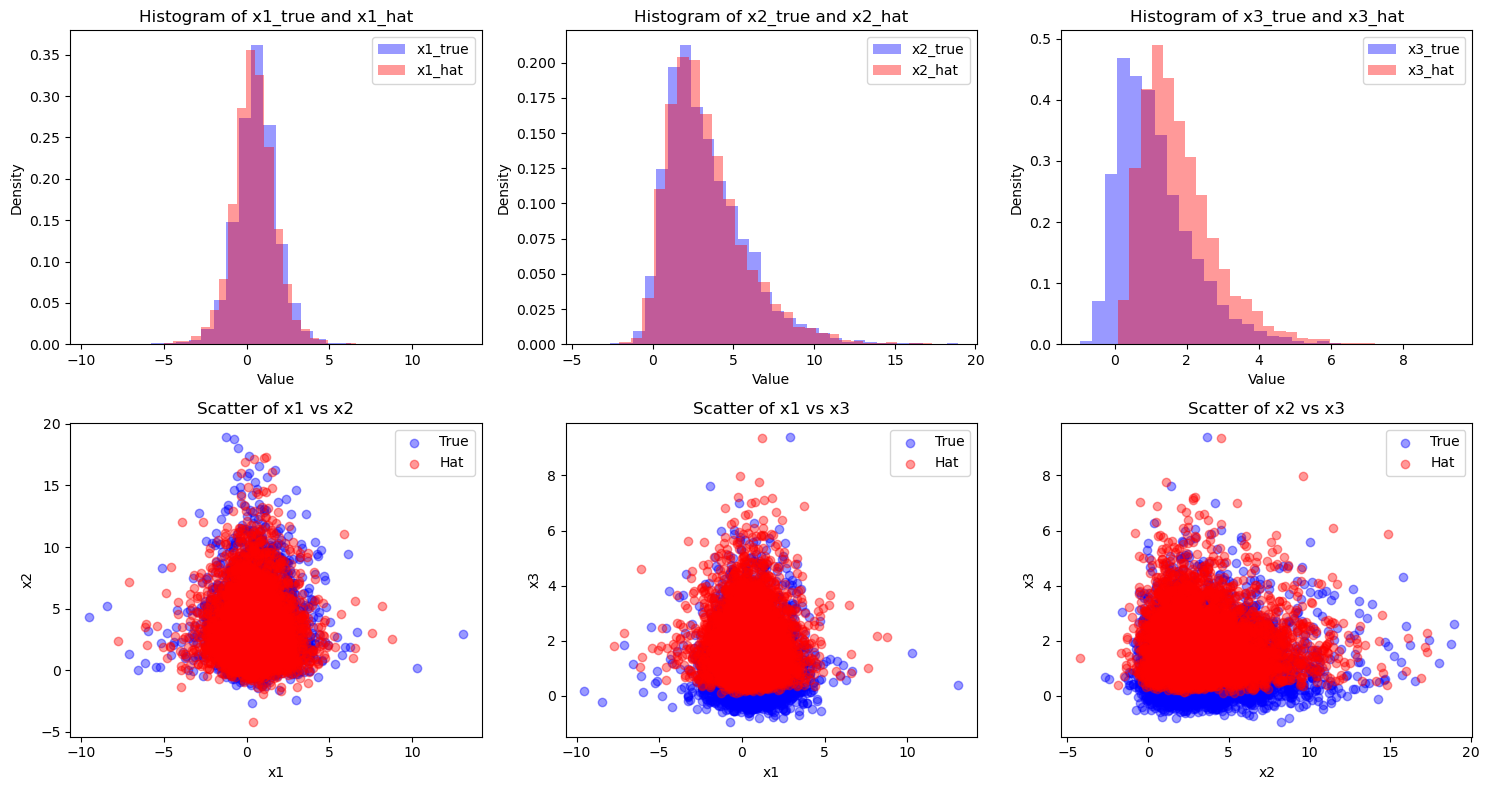

In [15]:
x1_true = generate_data(n_samples=5000, A_true=A_true[0].unsqueeze(0))
x1_hat = generate_data(n_samples=5000, A_true=torch.tensor(A_hat[0],dtype=torch.float32).unsqueeze(0))
x2_true = generate_data(n_samples=5000, A_true=A_true[1].unsqueeze(0))
x2_hat = generate_data(n_samples=5000, A_true=torch.tensor(A_hat[1],dtype=torch.float32).unsqueeze(0))
x3_true = generate_data(n_samples=5000, A_true=A_true[2].unsqueeze(0))
x3_hat = generate_data(n_samples=5000, A_true=torch.tensor(A_hat[2],dtype=torch.float32).unsqueeze(0))
x1_true = x1_true[:, 0].numpy()  # Shape: (5000,)
x1_hat = x1_hat[:, 0].numpy()    # Shape: (5000,)
x2_true = x2_true[:, 0].numpy()  # Shape: (5000,)
x2_hat = x2_hat[:, 0].numpy()    # Shape: (5000,)
x3_true = x3_true[:, 0].numpy()  # Shape: (5000,)
x3_hat = x3_hat[:, 0].numpy()    # Shape: (5000,)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

axes[0, 0].hist(x1_true, bins=30, color='blue', alpha=0.4, label='x1_true', density=True)
axes[0, 0].hist(x1_hat, bins=30, color='red', alpha=0.4, label='x1_hat', density=True)
axes[0, 0].set_xlabel('Value')
axes[0, 0].set_ylabel('Density')
axes[0, 0].set_title('Histogram of x1_true and x1_hat')
axes[0, 0].legend()

axes[0, 1].hist(x2_true, bins=30, color='blue', alpha=0.4, label='x2_true', density=True)
axes[0, 1].hist(x2_hat, bins=30, color='red', alpha=0.4, label='x2_hat', density=True)
axes[0, 1].set_xlabel('Value')
axes[0, 1].set_ylabel('Density')
axes[0, 1].set_title('Histogram of x2_true and x2_hat')
axes[0, 1].legend()

axes[0, 2].hist(x3_true, bins=30, color='blue', alpha=0.4, label='x3_true', density=True)
axes[0, 2].hist(x3_hat, bins=30, color='red', alpha=0.4, label='x3_hat', density=True)
axes[0, 2].set_xlabel('Value')
axes[0, 2].set_ylabel('Density')
axes[0, 2].set_title('Histogram of x3_true and x3_hat')
axes[0, 2].legend()

axes[1, 0].scatter(x1_true, x2_true, color='blue', alpha=0.4, label='True')
axes[1, 0].scatter(x1_hat, x2_hat, color='red', alpha=0.4, label='Hat')
axes[1, 0].set_xlabel('x1')
axes[1, 0].set_ylabel('x2')
axes[1, 0].set_title('Scatter of x1 vs x2')
axes[1, 0].legend()

axes[1, 1].scatter(x1_true, x3_true, color='blue', alpha=0.4, label='True')
axes[1, 1].scatter(x1_hat, x3_hat, color='red', alpha=0.4, label='Hat')
axes[1, 1].set_xlabel('x1')
axes[1, 1].set_ylabel('x3')
axes[1, 1].set_title('Scatter of x1 vs x3')
axes[1, 1].legend()

axes[1, 2].scatter(x2_true, x3_true, color='blue', alpha=0.4, label='True')
axes[1, 2].scatter(x2_hat, x3_hat, color='red', alpha=0.4, label='Hat')
axes[1, 2].set_xlabel('x2')
axes[1, 2].set_ylabel('x3')
axes[1, 2].set_title('Scatter of x2 vs x3')
axes[1, 2].legend()

plt.tight_layout()

plt.show()

In [17]:
model_formula_X = "x1 <- s1 + s2 + s3; x2 <- s1 + s2 + s3; x3 <- s1 + s2 + s3"
model_formula_S = "s1 ~ Gamma(2.0,1.0); s2 ~ Beta(2.0,5.0); s3 ~ StudentT(5.0);"
model_formula = model_formula_S + model_formula_X
model = SEM2(model_formula)
observed_var = ["x1", "x2", "x3"]
observed_index = [list(model.static_order()).index(var) for var in observed_var]
model = SEM2(model_formula)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-3)
model.train()
niter = 8000
for i in range(niter):
    optimizer.zero_grad()
    sample = model(X.size(0) * 2)[:, observed_index]
    loss, s1, s2 = energy_loss(X, sample,beta=1)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

model.eval()

A_hat = np.zeros([len(observed_var), len(observed_var)])
with torch.no_grad(): 
    for j, node in enumerate(observed_var):
        if model.node_dict[node] is not None:
            weights = model.node_dict[node].weight_matrix()[0].detach().cpu().numpy()
            A_hat[j, :] = weights.flatten()

AE = Amari_error(A_hat, A_true)
print(f"Amari_error: {AE:.4f}")

with torch.no_grad():  
    X_0p = generate_data(n_samples=20000, A_true=A_true)
    X_hat = generate_data(n_samples=20000, A_true=A_hat)
    loss_0, s1_0, s2_0 = energy_loss(X, X_0p)
    loss_1, s1_1, s2_1 = energy_loss(X, X_hat)
    print(f"True model, energy_loss: {loss_0:.4f}, s1: {s1_0:.4f}, s2: {s2_0:.4f}")
    print(f"Estimated model, energy_loss: {loss_1:.4f}, s1: {s1_1:.4f}, s2: {s2_1:.4f}")

Iter 1 | loss: 4.0417, s1: 4.7715, s2: 1.4596
Iter 1000 | loss: 1.7901, s1: 3.5010, s2: 3.4217
Iter 2000 | loss: 1.7465, s1: 3.4613, s2: 3.4296
Iter 3000 | loss: 1.7618, s1: 3.4805, s2: 3.4375
Iter 4000 | loss: 1.7412, s1: 3.4915, s2: 3.5007
Iter 5000 | loss: 1.7738, s1: 3.5159, s2: 3.4843
Iter 6000 | loss: 1.7694, s1: 3.5254, s2: 3.5120
Iter 7000 | loss: 1.7393, s1: 3.5065, s2: 3.5344
Iter 8000 | loss: 1.7720, s1: 3.5042, s2: 3.4644
Amari_error: 0.2120
True model, energy_loss: 1.7426, s1: 3.4928, s2: 3.5003
Estimated model, energy_loss: 1.7474, s1: 3.5056, s2: 3.5163


In [19]:
print(A_true)
print(A_hat)

tensor([[ 0.2552,  0.3053, -0.9678],
        [ 1.6748, -0.0532,  0.5116],
        [ 0.7336, -1.2597,  0.0221]])
[[ 0.24434906 -0.14793208 -0.97032773]
 [ 1.67547238 -0.07629159  0.55626023]
 [ 0.72786099 -1.34589386  0.0586367 ]]


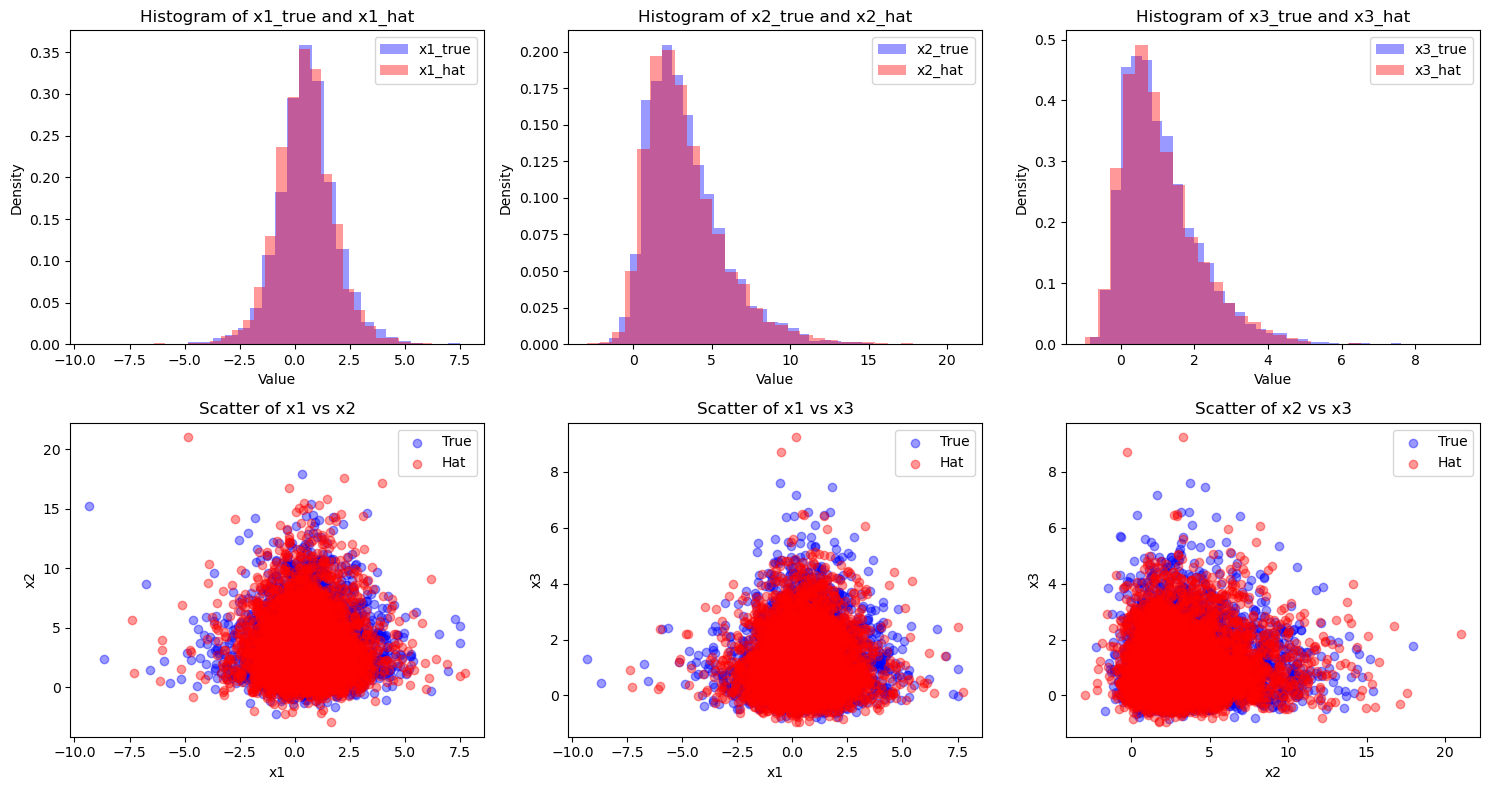

In [21]:
x1_true = generate_data(n_samples=5000, A_true=A_true[0].unsqueeze(0))
x1_hat = generate_data(n_samples=5000, A_true=torch.tensor(A_hat[0],dtype=torch.float32).unsqueeze(0))
x2_true = generate_data(n_samples=5000, A_true=A_true[1].unsqueeze(0))
x2_hat = generate_data(n_samples=5000, A_true=torch.tensor(A_hat[1],dtype=torch.float32).unsqueeze(0))
x3_true = generate_data(n_samples=5000, A_true=A_true[2].unsqueeze(0))
x3_hat = generate_data(n_samples=5000, A_true=torch.tensor(A_hat[2],dtype=torch.float32).unsqueeze(0))
x1_true = x1_true[:, 0].numpy()  # Shape: (5000,)
x1_hat = x1_hat[:, 0].numpy()    # Shape: (5000,)
x2_true = x2_true[:, 0].numpy()  # Shape: (5000,)
x2_hat = x2_hat[:, 0].numpy()    # Shape: (5000,)
x3_true = x3_true[:, 0].numpy()  # Shape: (5000,)
x3_hat = x3_hat[:, 0].numpy()    # Shape: (5000,)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

axes[0, 0].hist(x1_true, bins=30, color='blue', alpha=0.4, label='x1_true', density=True)
axes[0, 0].hist(x1_hat, bins=30, color='red', alpha=0.4, label='x1_hat', density=True)
axes[0, 0].set_xlabel('Value')
axes[0, 0].set_ylabel('Density')
axes[0, 0].set_title('Histogram of x1_true and x1_hat')
axes[0, 0].legend()

axes[0, 1].hist(x2_true, bins=30, color='blue', alpha=0.4, label='x2_true', density=True)
axes[0, 1].hist(x2_hat, bins=30, color='red', alpha=0.4, label='x2_hat', density=True)
axes[0, 1].set_xlabel('Value')
axes[0, 1].set_ylabel('Density')
axes[0, 1].set_title('Histogram of x2_true and x2_hat')
axes[0, 1].legend()

axes[0, 2].hist(x3_true, bins=30, color='blue', alpha=0.4, label='x3_true', density=True)
axes[0, 2].hist(x3_hat, bins=30, color='red', alpha=0.4, label='x3_hat', density=True)
axes[0, 2].set_xlabel('Value')
axes[0, 2].set_ylabel('Density')
axes[0, 2].set_title('Histogram of x3_true and x3_hat')
axes[0, 2].legend()

axes[1, 0].scatter(x1_true, x2_true, color='blue', alpha=0.4, label='True')
axes[1, 0].scatter(x1_hat, x2_hat, color='red', alpha=0.4, label='Hat')
axes[1, 0].set_xlabel('x1')
axes[1, 0].set_ylabel('x2')
axes[1, 0].set_title('Scatter of x1 vs x2')
axes[1, 0].legend()

axes[1, 1].scatter(x1_true, x3_true, color='blue', alpha=0.4, label='True')
axes[1, 1].scatter(x1_hat, x3_hat, color='red', alpha=0.4, label='Hat')
axes[1, 1].set_xlabel('x1')
axes[1, 1].set_ylabel('x3')
axes[1, 1].set_title('Scatter of x1 vs x3')
axes[1, 1].legend()

axes[1, 2].scatter(x2_true, x3_true, color='blue', alpha=0.4, label='True')
axes[1, 2].scatter(x2_hat, x3_hat, color='red', alpha=0.4, label='Hat')
axes[1, 2].set_xlabel('x2')
axes[1, 2].set_ylabel('x3')
axes[1, 2].set_title('Scatter of x2 vs x3')
axes[1, 2].legend()

plt.tight_layout()

plt.show()

In [ ]:
## the distributions of S is unknown; noise-free ICA

In [37]:
model_formula_X = "x1 <- s1 + s2 + s3; x2 <- s1 + s2 + s3; x3 <- s1 + s2 + s3"
model_formula_S = "u1, u2, u3 ~ Uniform(0.0, 1.0); s1 <- n(u1); s2 <- n(u2); s3 <- n(u3);"
model_formula = model_formula_S + model_formula_X
model = SEM2(model_formula)
observed_var = ["x1", "x2", "x3"]
observed_index = [list(model.static_order()).index(var) for var in observed_var]
model = SEM2(model_formula)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-3)
model.train()
niter = 3000
for i in range(niter):
    optimizer.zero_grad()
    sample = model(X.size(0) * 2)[:, observed_index]
    loss, s1, s2 = energy_loss(X, sample,beta=1/3)
    # sample1 = model(X.size(0))[:, observed_index]
    # sample2 = model(X.size(0))[:, observed_index]
    # loss, s1, s2 = energy_loss_two_sample(X, sample1,sample2,beta=1)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

model.eval()

A_hat = np.zeros([len(observed_var), len(observed_var)])
with torch.no_grad(): 
    for j, node in enumerate(observed_var):
        if model.node_dict[node] is not None:
            weights = model.node_dict[node].weight_matrix()[0].detach().cpu().numpy()
            A_hat[j, :] = weights.flatten()

AE = Amari_error(A_hat, A_true)
print(f"Amari_error: {AE:.4f}")


Iter 1 | loss: 1.4047, s1: 1.5429, s2: 0.2764
Iter 1000 | loss: 0.7151, s1: 1.4418, s2: 1.4535
Iter 2000 | loss: 0.7126, s1: 1.4392, s2: 1.4532
Iter 3000 | loss: 0.7129, s1: 1.4376, s2: 1.4494
Amari_error: 0.0726


In [39]:
print(A_true)
print(A_hat)

tensor([[ 0.2552,  0.3053, -0.9678],
        [ 1.6748, -0.0532,  0.5116],
        [ 0.7336, -1.2597,  0.0221]])
[[ 0.21750595  0.79331583  0.0653047 ]
 [-0.03613567 -0.42349815  0.44813859]
 [-0.54034835 -0.01797221  0.19401994]]


In [ ]:
## the distributions of S is unknown; homo_noisy ICA

In [139]:
n_components=3
cdn=5
A_true = generate_mixing_matrix(n_components, cdn)
Sigma=torch.diag(torch.tensor([0.25,0.64,0.09],dtype=torch.float32))
X = generate_data(n_samples=5000, A_true=A_true,Sigma=Sigma)

In [149]:
model_formula_X = "x1 <- 1*e1 + s1 + s2 +s3; x2 <- 1*e2 + s1 + s2 +s3; x3 <- 1*e3 + s1 + s2 +s3"
model_formula_e = "e1 ~ Normal(0.0, 0.5); e2 ~ Normal(0.0, 0.8);  e3 ~ Normal(0.0, 0.3);"
model_formula_S = "u1, u2, u3 ~ Uniform(0.0, 1.0); s1 <- n(u1); s2 <- n(u2); s3 <- n(u3);"
model_formula = model_formula_S + model_formula_e + model_formula_X
model = SEM2(model_formula)
observed_var = ["x1", "x2", "x3"]
observed_index = [list(model.static_order()).index(var) for var in observed_var]
model = SEM2(model_formula)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-3)
model.train()
niter = 4000
for i in range(niter):
    optimizer.zero_grad()
    sample = model(X.size(0) * 3)[:, observed_index]
    loss, s1, s2 = energy_loss(X, sample,beta=1)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

model.eval()

A_hat = np.zeros([len(observed_var), len(observed_var)])
with torch.no_grad(): 
    for j, node in enumerate(observed_var):
        if model.node_dict[node] is not None:
            weights = model.node_dict[node].weight_matrix()[0].detach().cpu().numpy().flatten()
            A_hat[j, :] = weights[1:(1+len(observed_var))]

AE = Amari_error(A_hat, A_true)
print(f"Amari_error: {AE:.4f}")

Iter 1 | loss: 8.6194, s1: 9.2459, s2: 1.2530
Iter 1000 | loss: 4.5870, s1: 8.8545, s2: 8.5351
Iter 2000 | loss: 4.5136, s1: 8.8848, s2: 8.7424
Iter 3000 | loss: 4.5700, s1: 9.1706, s2: 9.2013
Iter 4000 | loss: 4.5933, s1: 8.8424, s2: 8.4982
Amari_error: 0.0549


In [151]:
print(A_true)
print(A_hat)

tensor([[ 2.1125,  0.3827,  3.2414],
        [-1.2191, -1.9740,  3.1109],
        [-2.1563, -3.5457, -0.6501]])
[[-0.43739751  0.05075809 -0.48295698]
 [ 0.27685177 -0.20005827 -0.44849253]
 [ 0.46469811 -0.38784251  0.09748617]]


In [157]:
model_formula_X = "x1 <- 1*e1 + s1 + s2 +s3; x2 <- 1*e2 + s1 + s2 +s3; x3 <- 1*e3 + s1 + s2 +s3"
model_formula_e = "e1 ~ Normal(0.0, 0.5); e2 ~ Normal(0.0, 0.8);  e3 ~ Normal(0.0, 0.3);"
model_formula_S = "u1, u2, u3 ~ Uniform(0.0, 1.0); s1 <- n(u1); s2 <- n(u2); s3 <- n(u3);"
model_formula = model_formula_S + model_formula_e + model_formula_X
model = SEM2(model_formula)
observed_var = ["x1", "x2", "x3"]
observed_index = [list(model.static_order()).index(var) for var in observed_var]
model = SEM2(model_formula)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-3)
model.train()
niter = 4000
for i in range(niter):
    optimizer.zero_grad()
    sample = model(X.size(0) * 3)[:, observed_index]
    loss, s1, s2 = energy_loss(X, sample,beta=1)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

model.eval()

A_hat = np.zeros([len(observed_var), len(observed_var)])
with torch.no_grad(): 
    for j, node in enumerate(observed_var):
        if model.node_dict[node] is not None:
            weights = model.node_dict[node].weight_matrix()[0].detach().cpu().numpy().flatten()
            A_hat[j, :] = weights[1:(1+len(observed_var))]

AE = Amari_error(A_hat, A_true)
print(f"Amari_error: {AE:.4f}")

Iter 1 | loss: 9.0767, s1: 9.7066, s2: 1.2597
Iter 1000 | loss: 4.5823, s1: 8.9048, s2: 8.6450
Iter 2000 | loss: 4.5294, s1: 8.9438, s2: 8.8287
Iter 3000 | loss: 4.5562, s1: 8.9409, s2: 8.7693
Iter 4000 | loss: 4.5881, s1: 9.0406, s2: 8.9051
Amari_error: 0.4240


In [159]:
print(A_true)
print(A_hat)

tensor([[ 2.1125,  0.3827,  3.2414],
        [-1.2191, -1.9740,  3.1109],
        [-2.1563, -3.5457, -0.6501]])
[[-0.08394764  0.4593969   0.29604888]
 [ 0.01710959 -0.29031518  0.2757692 ]
 [ 0.08633729 -0.4900139  -0.05589107]]


In [ ]:
## the distributions of S is unknown; homo_noisy ICA (data_size=10000 and ∑ =diag([0.25,0.64,1.0]))

In [41]:
n_components=3
cdn=3
A_true = generate_mixing_matrix(n_components, cdn)
Sigma=torch.diag(torch.tensor([0.25,0.64,1.0],dtype=torch.float32))
X = generate_data(n_samples=10000, A_true=A_true,Sigma=Sigma)

In [55]:
model_formula_X = "x1 <- 1*e1 + s1 + s2 +s3; x2 <- 1*e2 + s1 + s2 +s3; x3 <- 1*e3 + s1 + s2 +s3"
model_formula_e = "e1 ~ Normal(0.0, 0.5); e2 ~ Normal(0.0, 0.8);  e3 ~ Normal(0.0, 1.0);"
model_formula_S = "u1, u2, u3 ~ Uniform(0.0, 1.0); s1 <- n(u1); s2 <- n(u2); s3 <- n(u3);"
model_formula = model_formula_S + model_formula_e + model_formula_X
model = SEM2(model_formula)
observed_var = ["x1", "x2", "x3"]
observed_index = [list(model.static_order()).index(var) for var in observed_var]
model = SEM2(model_formula)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-3)
model.train()
niter = 3000
for i in range(niter):
    optimizer.zero_grad()
    sample = model(X.size(0) * 2)[:, observed_index]
    loss, s1, s2 = energy_loss(X, sample,beta=1/2)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

model.eval()

A_hat = np.zeros([len(observed_var), len(observed_var)])
with torch.no_grad(): 
    for j, node in enumerate(observed_var):
        if model.node_dict[node] is not None:
            weights = model.node_dict[node].weight_matrix()[0].detach().cpu().numpy().flatten()
            A_hat[j, :] = weights[1:(1+len(observed_var))]

AE = Amari_error(A_hat, A_true)
print(f"Amari_error: {AE:.4f}")

Iter 1 | loss: 1.4193, s1: 2.0671, s2: 1.2956
Iter 1000 | loss: 1.0688, s1: 2.1172, s2: 2.0968
Iter 2000 | loss: 1.0700, s1: 2.1256, s2: 2.1113
Iter 3000 | loss: 1.0652, s1: 2.1277, s2: 2.1250
Amari_error: 0.3660


In [57]:
print(A_true)
print(A_hat)

tensor([[-0.8544,  1.9440, -1.2489],
        [ 0.0683,  0.4882, -1.6527],
        [-1.6774,  0.1451, -0.5864]])
[[ 0.29633638  0.18676731 -0.25333774]
 [-0.00544427  0.33129734 -0.32039502]
 [ 0.55220616 -0.10728172 -0.14796832]]


In [65]:
model_formula_X = "x1 <- 1*e1 + s1 + s2 +s3; x2 <- 1*e2 + s1 + s2 +s3; x3 <- 1*e3 + s1 + s2 +s3"
model_formula_e = "e1 ~ Normal(0.0, 0.5); e2 ~ Normal(0.0, 0.8);  e3 ~ Normal(0.0, 1.0);"
model_formula_S = "u1, u2, u3 ~ Uniform(0.0, 1.0); s1 <- n(u1); s2 <- n(u2); s3 <- n(u3);"
model_formula = model_formula_S + model_formula_e + model_formula_X
model = SEM2(model_formula)
observed_var = ["x1", "x2", "x3"]
observed_index = [list(model.static_order()).index(var) for var in observed_var]
model = SEM2(model_formula)
optimizer = torch.optim.Adam(model.parameters(), lr=7e-3)
model.train()
niter = 8000
for i in range(niter):
    optimizer.zero_grad()
    sample = model(X.size(0) * 2)[:, observed_index]
    loss, s1, s2 = energy_loss(X, sample,beta=1)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

model.eval()

A_hat = np.zeros([len(observed_var), len(observed_var)])
with torch.no_grad(): 
    for j, node in enumerate(observed_var):
        if model.node_dict[node] is not None:
            weights = model.node_dict[node].weight_matrix()[0].detach().cpu().numpy().flatten()
            A_hat[j, :] = weights[1:(1+len(observed_var))]

AE = Amari_error(A_hat, A_true)
print(f"Amari_error: {AE:.4f}")

Iter 1 | loss: 4.2905, s1: 5.1745, s2: 1.7681
Iter 1000 | loss: 2.5202, s1: 4.8821, s2: 4.7239
Iter 2000 | loss: 2.4999, s1: 4.9221, s2: 4.8443
Iter 3000 | loss: 2.4993, s1: 4.9854, s2: 4.9723
Iter 4000 | loss: 2.5004, s1: 4.9577, s2: 4.9147
Iter 5000 | loss: 2.4965, s1: 4.8657, s2: 4.7385
Iter 6000 | loss: 2.5026, s1: 4.8835, s2: 4.7619
Iter 7000 | loss: 2.5193, s1: 4.9765, s2: 4.9144
Iter 8000 | loss: 2.5062, s1: 4.9712, s2: 4.9300
Amari_error: 0.3543


In [67]:
print(A_true)
print(A_hat)

tensor([[-0.8544,  1.9440, -1.2489],
        [ 0.0683,  0.4882, -1.6527],
        [-1.6774,  0.1451, -0.5864]])
[[-0.45188347 -0.27034011  0.20169359]
 [-0.59582901 -0.32934394 -0.03301889]
 [-0.2109428   0.48686063  0.4025183 ]]


In [ ]:
##use energy_loss_two_sample to calculate loss

In [101]:
model_formula_X = "x1 <- 1*e1 + s1 + s2 +s3; x2 <- 1*e2 + s1 + s2 +s3; x3 <- 1*e3 + s1 + s2 +s3"
model_formula_e = "e1 ~ Normal(0.0, 0.5); e2 ~ Normal(0.0, 0.8);  e3 ~ Normal(0.0, 1.0);"
model_formula_S = "u1, u2, u3 ~ Uniform(0.0, 1.0); s1 <- n(u1); s2 <- n(u2); s3 <- n(u3);"
model_formula = model_formula_S + model_formula_e + model_formula_X
model = SEM2(model_formula)
observed_var = ["x1", "x2", "x3"]
observed_index = [list(model.static_order()).index(var) for var in observed_var]
model = SEM2(model_formula)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-3)
model.train()
niter = 8000
for i in range(niter):
    optimizer.zero_grad()
    sample1 = model(X.size(0))[:, observed_index]
    sample2 = model(X.size(0))[:, observed_index]
    loss, s1, s2 = energy_loss_two_sample(X, sample1,sample2,beta=1)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

model.eval()

A_hat = np.zeros([len(observed_var), len(observed_var)])
with torch.no_grad(): 
    for j, node in enumerate(observed_var):
        if model.node_dict[node] is not None:
            weights = model.node_dict[node].weight_matrix()[0].detach().cpu().numpy().flatten()
            A_hat[j, :] = weights[1:(1+len(observed_var))]

AE = Amari_error(A_hat, A_true)
print(f"Amari_error: {AE:.4f}")

Iter 1 | loss: 3.8339, s1: 4.7203, s2: 1.7727
Iter 1000 | loss: 2.4950, s1: 4.9020, s2: 4.8140
Iter 2000 | loss: 2.4754, s1: 4.9103, s2: 4.8697
Iter 3000 | loss: 2.4851, s1: 4.9255, s2: 4.8807
Iter 4000 | loss: 2.4920, s1: 4.9623, s2: 4.9406
Iter 5000 | loss: 2.4948, s1: 4.8948, s2: 4.8000
Iter 6000 | loss: 2.4992, s1: 4.9588, s2: 4.9191
Iter 7000 | loss: 2.5014, s1: 4.9817, s2: 4.9605
Iter 8000 | loss: 2.4678, s1: 4.9137, s2: 4.8918
Amari_error: 0.5037


In [115]:
model_formula_X = "x1 <- 1*e1 + s1 + s2 +s3; x2 <- 1*e2 + s1 + s2 +s3; x3 <- 1*e3 + s1 + s2 +s3"
model_formula_e = "e1 ~ Normal(0.0, 0.5); e2 ~ Normal(0.0, 0.8);  e3 ~ Normal(0.0, 1.0);"
model_formula_S = "u1, u2, u3 ~ Uniform(0.0, 1.0); s1 <- n(u1); s2 <- n(u2); s3 <- n(u3);"
model_formula = model_formula_S + model_formula_e + model_formula_X
model = SEM2(model_formula)
observed_var = ["x1", "x2", "x3"]
observed_index = [list(model.static_order()).index(var) for var in observed_var]
model = SEM2(model_formula)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
model.train()
niter = 6000
for i in range(niter):
    optimizer.zero_grad()
    sample1 = model(X.size(0))[:, observed_index]
    sample2 = model(X.size(0))[:, observed_index]
    loss, s1, s2 = energy_loss_two_sample(X, sample1,sample2,beta=1)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

model.eval()

A_hat = np.zeros([len(observed_var), len(observed_var)])
with torch.no_grad(): 
    for j, node in enumerate(observed_var):
        if model.node_dict[node] is not None:
            weights = model.node_dict[node].weight_matrix()[0].detach().cpu().numpy().flatten()
            A_hat[j, :] = weights[1:(1+len(observed_var))]

AE = Amari_error(A_hat, A_true)
print(f"Amari_error: {AE:.4f}")

Iter 1 | loss: 3.7140, s1: 4.5914, s2: 1.7547
Iter 1000 | loss: 2.4932, s1: 4.9185, s2: 4.8506
Iter 2000 | loss: 2.4971, s1: 4.8375, s2: 4.6807
Iter 3000 | loss: 2.5140, s1: 4.9343, s2: 4.8406
Iter 4000 | loss: 2.5099, s1: 4.9724, s2: 4.9250
Iter 5000 | loss: 2.5224, s1: 4.9885, s2: 4.9323
Iter 6000 | loss: 2.4872, s1: 4.9758, s2: 4.9772
Amari_error: 0.4913


In [117]:
print(A_true)
print(A_hat)

tensor([[-0.8544,  1.9440, -1.2489],
        [ 0.0683,  0.4882, -1.6527],
        [-1.6774,  0.1451, -0.5864]])
[[ 0.27795798  0.24105589  0.24516097]
 [ 0.35848337 -0.17984536 -0.00155788]
 [ 0.1424067  -0.39541098  0.45849138]]


In [ ]:
##use lr_scheduler 

In [83]:
from torch.optim.lr_scheduler import ReduceLROnPlateau

model_formula_X = "x1 <- 1*e1 + s1 + s2 +s3; x2 <- 1*e2 + s1 + s2 +s3; x3 <- 1*e3 + s1 + s2 +s3"
model_formula_e = "e1 ~ Normal(0.0, 0.5); e2 ~ Normal(0.0, 0.8);  e3 ~ Normal(0.0, 1.0);"
model_formula_S = "u1, u2, u3 ~ Uniform(0.0, 1.0); s1 <- n(u1); s2 <- n(u2); s3 <- n(u3);"
model_formula = model_formula_S + model_formula_e + model_formula_X
model = SEM2(model_formula)
observed_var = ["x1", "x2", "x3"]
observed_index = [list(model.static_order()).index(var) for var in observed_var]
model = SEM2(model_formula)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.7, patience=500, 
                              threshold=1e-4, min_lr=1e-5, verbose=True)
model.train()
niter = 3500
for i in range(niter):
    optimizer.zero_grad()
    sample = model(X.size(0) * 2)[:, observed_index]
    loss, s1, s2 = energy_loss(X, sample,beta=1)
    loss.backward()
    optimizer.step()
    scheduler.step(loss)
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

model.eval()

A_hat = np.zeros([len(observed_var), len(observed_var)])
with torch.no_grad(): 
    for j, node in enumerate(observed_var):
        if model.node_dict[node] is not None:
            weights = model.node_dict[node].weight_matrix()[0].detach().cpu().numpy().flatten()
            A_hat[j, :] = weights[1:(1+len(observed_var))]

AE = Amari_error(A_hat, A_true)
print(f"Amari_error: {AE:.4f}")

Iter 1 | loss: 4.0558, s1: 4.9388, s2: 1.7659
Iter 1000 | loss: 2.5079, s1: 4.8393, s2: 4.6628
Iter 2000 | loss: 2.4740, s1: 4.9649, s2: 4.9818
Iter 3000 | loss: 2.4666, s1: 4.9106, s2: 4.8881
Amari_error: 0.3142


In [85]:
print(A_true)
print(A_hat)

tensor([[-0.8544,  1.9440, -1.2489],
        [ 0.0683,  0.4882, -1.6527],
        [-1.6774,  0.1451, -0.5864]])
[[ 0.29415724 -0.17778142  0.05359742]
 [ 0.40763304 -0.007759   -0.12255289]
 [ 0.11226321 -0.32116744  0.17762303]]


In [121]:
from torch.optim.lr_scheduler import ReduceLROnPlateau

model_formula_X = "x1 <- 1*e1 + s1 + s2 +s3; x2 <- 1*e2 + s1 + s2 +s3; x3 <- 1*e3 + s1 + s2 +s3"
model_formula_e = "e1 ~ Normal(0.0, 0.5); e2 ~ Normal(0.0, 0.8);  e3 ~ Normal(0.0, 1.0);"
model_formula_S = "u1, u2, u3 ~ Uniform(0.0, 1.0); s1 <- n(u1); s2 <- n(u2); s3 <- n(u3);"
model_formula = model_formula_S + model_formula_e + model_formula_X
model = SEM2(model_formula)
observed_var = ["x1", "x2", "x3"]
observed_index = [list(model.static_order()).index(var) for var in observed_var]
model = SEM2(model_formula)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.8, patience=800, 
                              threshold=1e-4, min_lr=1e-5, verbose=True)
model.train()
niter = 5000
for i in range(niter):
    optimizer.zero_grad()
    sample = model(X.size(0) * 2)[:, observed_index]
    loss, s1, s2 = energy_loss(X, sample,beta=1)
    loss.backward()
    optimizer.step()
    scheduler.step(loss)
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

model.eval()

A_hat = np.zeros([len(observed_var), len(observed_var)])
with torch.no_grad(): 
    for j, node in enumerate(observed_var):
        if model.node_dict[node] is not None:
            weights = model.node_dict[node].weight_matrix()[0].detach().cpu().numpy().flatten()
            A_hat[j, :] = weights[1:(1+len(observed_var))]

AE = Amari_error(A_hat, A_true)
print(f"Amari_error: {AE:.4f}")

Iter 1 | loss: 3.9153, s1: 4.7990, s2: 1.7673
Iter 1000 | loss: 2.4818, s1: 4.9416, s2: 4.9196
Iter 2000 | loss: 2.4873, s1: 4.9063, s2: 4.8379
Iter 3000 | loss: 2.4821, s1: 4.9264, s2: 4.8887
Iter 4000 | loss: 2.4989, s1: 4.9527, s2: 4.9076
Iter 5000 | loss: 2.4810, s1: 4.8945, s2: 4.8269
Amari_error: 0.3787


In [123]:
print(A_true)
print(A_hat)

tensor([[-0.8544,  1.9440, -1.2489],
        [ 0.0683,  0.4882, -1.6527],
        [-1.6774,  0.1451, -0.5864]])
[[-0.26272371 -0.21726835 -0.29780287]
 [-0.0179413   0.01249591 -0.39011294]
 [ 0.35526255 -0.41551691 -0.14795925]]


In [97]:
from torch.optim.lr_scheduler import CosineAnnealingLR

model_formula_X = "x1 <- 1*e1 + s1 + s2 +s3; x2 <- 1*e2 + s1 + s2 +s3; x3 <- 1*e3 + s1 + s2 +s3"
model_formula_e = "e1 ~ Normal(0.0, 0.5); e2 ~ Normal(0.0, 0.8);  e3 ~ Normal(0.0, 1.0);"
model_formula_S = "u1, u2, u3 ~ Uniform(0.0, 1.0); s1 <- n(u1); s2 <- n(u2); s3 <- n(u3);"
model_formula = model_formula_S + model_formula_e + model_formula_X
model = SEM2(model_formula)
observed_var = ["x1", "x2", "x3"]
observed_index = [list(model.static_order()).index(var) for var in observed_var]
model = SEM2(model_formula)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
scheduler = CosineAnnealingLR(optimizer, T_max=1000, eta_min=1e-5, verbose=True)
model.train()
niter = 2000
for i in range(niter):
    optimizer.zero_grad()
    sample = model(X.size(0) * 2)[:, observed_index]
    loss, s1, s2 = energy_loss(X, sample,beta=1)
    loss.backward()
    optimizer.step()
    scheduler.step()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

model.eval()

A_hat = np.zeros([len(observed_var), len(observed_var)])
with torch.no_grad(): 
    for j, node in enumerate(observed_var):
        if model.node_dict[node] is not None:
            weights = model.node_dict[node].weight_matrix()[0].detach().cpu().numpy().flatten()
            A_hat[j, :] = weights[1:(1+len(observed_var))]

AE = Amari_error(A_hat, A_true)
print(f"Amari_error: {AE:.4f}")

Iter 1 | loss: 3.9537, s1: 4.8369, s2: 1.7662
Iter 1000 | loss: 2.5118, s1: 4.8891, s2: 4.7546
Iter 2000 | loss: 2.4809, s1: 4.9376, s2: 4.9135
Amari_error: 0.5962


In [95]:
print(A_true)
print(A_hat)

tensor([[-0.8544,  1.9440, -1.2489],
        [ 0.0683,  0.4882, -1.6527],
        [-1.6774,  0.1451, -0.5864]])
[[-0.2497272   0.23910864  0.01964892]
 [-0.29642442 -0.01791294  0.38245663]
 [-0.13397646  0.46615496 -0.5184145 ]]


In [125]:
from torch.optim.lr_scheduler import CosineAnnealingLR

model_formula_X = "x1 <- 1*e1 + s1 + s2 +s3; x2 <- 1*e2 + s1 + s2 +s3; x3 <- 1*e3 + s1 + s2 +s3"
model_formula_e = "e1 ~ Normal(0.0, 0.5); e2 ~ Normal(0.0, 0.8);  e3 ~ Normal(0.0, 1.0);"
model_formula_S = "u1, u2, u3 ~ Uniform(0.0, 1.0); s1 <- n(u1); s2 <- n(u2); s3 <- n(u3);"
model_formula = model_formula_S + model_formula_e + model_formula_X
model = SEM2(model_formula)
observed_var = ["x1", "x2", "x3"]
observed_index = [list(model.static_order()).index(var) for var in observed_var]
model = SEM2(model_formula)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
scheduler = CosineAnnealingLR(optimizer, T_max=2000, eta_min=1e-5, verbose=True)
model.train()
niter = 4000
for i in range(niter):
    optimizer.zero_grad()
    sample = model(X.size(0) * 2)[:, observed_index]
    loss, s1, s2 = energy_loss(X, sample,beta=1)
    loss.backward()
    optimizer.step()
    scheduler.step()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

model.eval()

A_hat = np.zeros([len(observed_var), len(observed_var)])
with torch.no_grad(): 
    for j, node in enumerate(observed_var):
        if model.node_dict[node] is not None:
            weights = model.node_dict[node].weight_matrix()[0].detach().cpu().numpy().flatten()
            A_hat[j, :] = weights[1:(1+len(observed_var))]

AE = Amari_error(A_hat, A_true)
print(f"Amari_error: {AE:.4f}")

Iter 1 | loss: 4.3290, s1: 5.2128, s2: 1.7676
Iter 1000 | loss: 2.4993, s1: 4.9509, s2: 4.9032
Iter 2000 | loss: 2.4888, s1: 4.9101, s2: 4.8425
Iter 3000 | loss: 2.4894, s1: 4.9041, s2: 4.8294
Iter 4000 | loss: 2.5035, s1: 4.8647, s2: 4.7223
Amari_error: 0.5382


In [127]:
print(A_true)
print(A_hat)

tensor([[-0.8544,  1.9440, -1.2489],
        [ 0.0683,  0.4882, -1.6527],
        [-1.6774,  0.1451, -0.5864]])
[[0.25321555 0.28034124 0.09048457]
 [0.36117753 0.02585762 0.16049063]
 [0.09433147 0.49481088 0.35798633]]
